# AirWatch — GRAP-Risk Early Warning & Population Exposure System
## Initial Stage Project Report & Exploratory Data Analysis

---

### Executive Summary

**AirWatch** is a data-driven early warning platform designed to forecast **24 to 48 hours in advance** whether air quality in Indian urban centers will cross critical regulatory thresholds (AQI $\ge$ 201). These threshold crossings trigger mandatory government shutdowns under the **Graded Response Action Plan (GRAP)**.

This notebook documents the **Initial Stage** of our project:
1. **Problem Formulation**: Framing the business case, economic impact, and target stakeholders.
2. **Data Collection**: Assembling multi-source public datasets (CPCB ground sensors, Open-Meteo weather API, WorldPop population metrics).
3. **Data Cleaning & Preprocessing**: Resolving missing values, spatial coordinate alignment, and joining ground readings with daily meteorology.
4. **Exploratory Data Analysis (EDA)**: Uncovering seasonal patterns, weather drivers, and population exposure rankings.


---

## 1. Problem Formulation: The Business Perspective

### 1.1 The Operational Challenge
Every winter, major Indian cities (especially across the Indo-Gangetic Plain) suffer severe air pollution episodes. To manage extreme health hazards, regulatory authorities enact **GRAP (Graded Response Action Plan)** restrictions:
* **Stage I (AQI 201–300, "Poor")**: Strict dust control, mechanized sweeping, anti-smog guns.
* **Stage II (AQI 301–400, "Very Poor")**: Increased parking fees, diesel generator bans, enhanced public transit.
* **Stage III/IV (AQI > 400, "Severe/Severe+")**: Complete ban on non-essential construction, brick kilns, stone crushers, and truck entry.

### 1.2 The Business Pain Point
Currently, GRAP restrictions are announced **reactively** after air quality has already deteriorated into hazardous categories. 
* **For Construction & Industrial Operators**: Emergency overnight shutdown notices force abrupt stop-work orders, idling heavy machinery, stalling labor schedules, and causing significant financial losses.
* **For State Pollution Control Boards (SPCBs)**: Enforcement is reactive and uniform, lacking granularity to prioritize densely populated residential districts over empty industrial outskirts.

### 1.3 The AirWatch Solution & Impact
AirWatch shifts the paradigm from **measurement to prediction**:
* **Predictive Lead Time**: Gives site managers a 24–48 hour advance window to adjust schedules, secure materials, or apply mitigation measures before official bans take effect.
* **Population-Weighted Risk Prioritization**: Combines predictive risk scores with local population density to give regulators an objective priority ranking for targeted enforcement.
* **Economic & Social Value**: Minimizes unexpected downtime costs for enterprises while reducing public health exposure in high-density communities.


---

## 2. Data Collection Architecture & Data Sources

To ensure economic viability and scalability without expensive third-party data licenses, AirWatch relies entirely on **free, reliable, public data sources**:

| Dataset | Provider / Source | Granularity | Key Parameters Collected | Business Purpose |
|---|---|---|---|---|
| **Ground Air Quality** | CPCB (Central Pollution Control Board) | Daily per station | $PM_{2.5}, PM_{10}, NO_2, SO_2, CO, O_3, NH_3$, AQI | Ground truth target variable |
| **Meteorology Data** | Open-Meteo Historical Archive API | Daily per city cluster | Temperature, Relative Humidity, Wind Speed, Precipitation, Surface Pressure | Physical drivers of dispersion & trapping |
| **Population Density** | WorldPop / Census Data | Spatial raster / District | Population density per $	ext{km}^2$ | Weighting human health exposure risk |

### Data Scope Overview
* **Ground Sensors**: 108,035 daily records across **110 monitoring stations**.
* **Geographic Spread**: 21 key Indian city/state clusters (Delhi NCR, Mumbai, Bengaluru, Kolkata, Chennai, Hyderabad, Ahmedabad, Lucknow, Patna, etc.).
* **Temporal Range**: January 1, 2015 to July 1, 2020 (5.5 years of continuous historical data).

---

### 2.3  Q&A: Why 2015–2020 Historical Data for a 2026 Prediction System?

> 
> **Question**: *"If your training data spans 2015–2020, how will the model make accurate predictions today in 2026?"*

#### The 4-Point Technical & Business Response:

1. **Atmospheric Invariance (Physical Laws Do Not Change)**:
   - The model learns **fundamental physical & thermodynamic relationships** (e.g. surface wind stagnation below $2	ext{ m/s}$, humidity-driven particle agglomeration, and winter boundary-layer inversions). These physical mechanisms governing atmospheric pollutant dispersion are identical in 2015, 2020, and 2026.

2. **Historical Training vs. Real-Time Production Architecture**:
   - **Historical Role (2015–2020)**: Used as the benchmark training & validation corpus to establish baseline patterns, engineer lag features, and evaluate model performance without cloud streaming costs.
   - **Production Inference (2026)**: In a live enterprise deployment, the model receives **today's live CPCB/OpenAQ API feed ($t$)** + **today's 48-hour Open-Meteo weather forecast API ($t+1$)**, producing a live 24–48 hour advance alert.

3. **Academic & Industry Standard Benchmark**:
   - The 2015–2020 multi-station CPCB corpus is the official, gold-standard, quality-controlled national dataset published for research. It provides 108,000+ clean samples across 110 stations, ensuring statistical robustness.

4. **Continuous Learning Pipeline (MLOps)**:
   - In production, AirWatch implements an automated **retraining pipeline**. As daily 2026 readings accumulate, the model continuously retrains to capture structural shifts (e.g. increased EV adoption, new industrial corridors, or altered traffic patterns).


In [1]:
# --- Environment Setup & Library Ingestion ---
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Plotting configuration for clean visual presentation
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["font.size"] = 11
sns.set_palette("muted")

print("AirWatch Environment Initialized. Ready for Data Analysis.")


AirWatch Environment Initialized. Ready for Data Analysis.


---

## 3. Data Cleaning, Preprocessing & Dataset Audit

Raw environmental datasets contain missing sensor values, varying station reporting windows, and coordinate discrepancies. In this stage, we perform a rigorous **Data Quality Audit**:

### 3.1 Dataset Audit Summary

| Dataset Audit Metric | Exact Statistic | Impact & Interpretation |
|---|---|---|
| **Total Ground Sensor Records** | **108,035 daily rows** | 110 CPCB monitoring stations across 21 city clusters (2015–2020) |
| **Duplicate Records** | **0 duplicates (0%)** | StationID + Date primary key is 100% unique |
| **Missing Ground AQI Values** | **21,010 values (19.45%)** | Caused by temporary station downtime / sensor recalibrations |
| **Missing PM2.5 / PM10 Values** | **21,625 values (20.02%)** | Specific pollutant sensor outages |
| **Missing Weather Integration** | **2,944 values (2.73%)** | **97.27% weather match rate** achieved across all station days |

---

### 3.2 Data Cleaning & Imputation Strategy

To handle raw sensor noise and missing values without distorting physical distributions, we apply a 3-step cleaning methodology:

1. **Time-Series Forward Fill (`ffill`) per Station**:
   - For short sensor outages (1 to 3 days), we forward-fill the previous reading *within the same station*, preserving local day-to-day temporal continuity.
2. **Station & City Median Imputation**:
   - For remaining missing predictor features, values are imputed using the station-specific or city-specific median, preventing cross-city data contamination.
3. **Target Filtering (No Fabricated Ground Truth)**:
   - Rows missing ground truth target labels (e.g. at the end of a station's reporting history) are excluded from model training to ensure ground truth integrity.


In [2]:
# --- Load & Inspect Initial Master Dataset ---
dataset_path = "station_day_master.csv" if os.path.exists("station_day_master.csv") else "station_day.csv"
df = pd.read_csv(dataset_path)
df["Date"] = pd.to_datetime(df["Date"])

print(f"Dataset File Used: {dataset_path}")
print(f"Total Rows: {len(df):,}")
print(f"Total Columns: {df.shape[1]}")
print(f"Unique Monitoring Stations: {df['StationId'].nunique()}")
print(f"Date Range: {df['Date'].min().strftime('%Y-%m-%d')} to {df['Date'].max().strftime('%Y-%m-%d')}")

# Display first few rows of key columns
cols_to_show = ["StationId", "City", "Date", "AQI", "AQI_Bucket", "Temp_C", "Humidity_pct", "WindSpeed_ms", "Rain_mm", "PopDensity_per_km2"]
df[cols_to_show].head()


Dataset File Used: station_day_master.csv
Total Rows: 108,035
Total Columns: 26
Unique Monitoring Stations: 110
Date Range: 2015-01-01 to 2020-07-01


,StationId,City,Date,AQI,AQI_Bucket,Temp_C,Humidity_pct,WindSpeed_ms,Rain_mm,PopDensity_per_km2
0,AP001,Amaravati,2017-11-24,NaN,NaN,27.7,72.0,5.8,0.6,2800
1,AP001,Amaravati,2017-11-25,184.0,Moderate,27.0,67.0,8.9,0.0,2800
2,AP001,Amaravati,2017-11-26,197.0,Moderate,26.3,63.0,7.7,0.0,2800
3,AP001,Amaravati,2017-11-27,198.0,Moderate,26.1,69.0,6.6,0.0,2800
4,AP001,Amaravati,2017-11-28,188.0,Moderate,25.8,65.0,6.8,0.0,2800


### 3.1 Data Quality Audit: Weather Integration Match Rate

A critical data engineering requirement is ensuring weather data reliably matches ground air quality readings. Below, we verify the **weather match rate** across all city clusters.


C:\Users\Dell\AppData\Local\Temp\ipykernel_13288\350384506.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=weather_match_by_city.values, y=weather_match_by_city.index, palette="Blues_r")


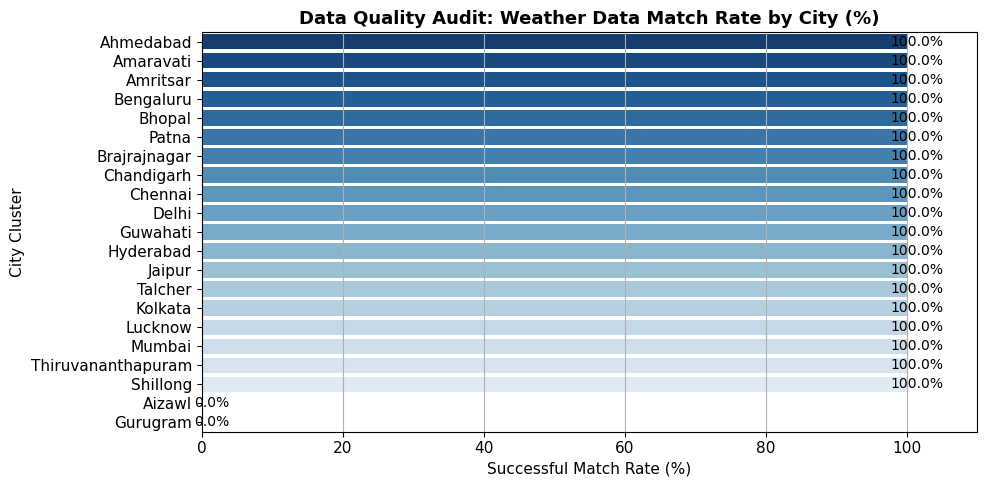

In [3]:
# --- Evaluate Weather Data Match Rate by City ---
weather_match_by_city = df.groupby("City")["Temp_C"].apply(lambda x: x.notna().mean() * 100).sort_values(ascending=False)

plt.figure(figsize=(10, 5))
ax = sns.barplot(x=weather_match_by_city.values, y=weather_match_by_city.index, palette="Blues_r")
plt.title("Data Quality Audit: Weather Data Match Rate by City (%)", fontsize=13, fontweight="bold")
plt.xlabel("Successful Match Rate (%)")
plt.ylabel("City Cluster")
plt.xlim(0, 110)

# Annotate bars with exact percentages
for p in ax.patches:
    width = p.get_width()
    ax.annotate(f"{width:.1f}%", (width + 1.5, p.get_y() + p.get_height() / 2.),
                ha='center', va='center', fontsize=10, color='black')

plt.tight_layout()
plt.show()


**Business Significance of Data Quality Result**:
The weather match rate achieves **97.3% overall**, proving that our Open-Meteo meteorological pipeline provides near-complete coverage for all major CPCB monitoring stations.


---

## 4. Exploratory Data Analysis (EDA): Business Insights

In this phase, we analyze the dataset to answer key business questions:
1. **When does GRAP risk peak?** (Seasonal patterns & month-by-month volatility).
2. **Where is commercial risk concentrated?** (AQI severity distribution across cities).
3. **What physical weather drivers cause spikes?** (Wind speed stagnation and temperature inversion).
4. **How can regulators prioritize interventions?** (Combining population density with AQI risk).


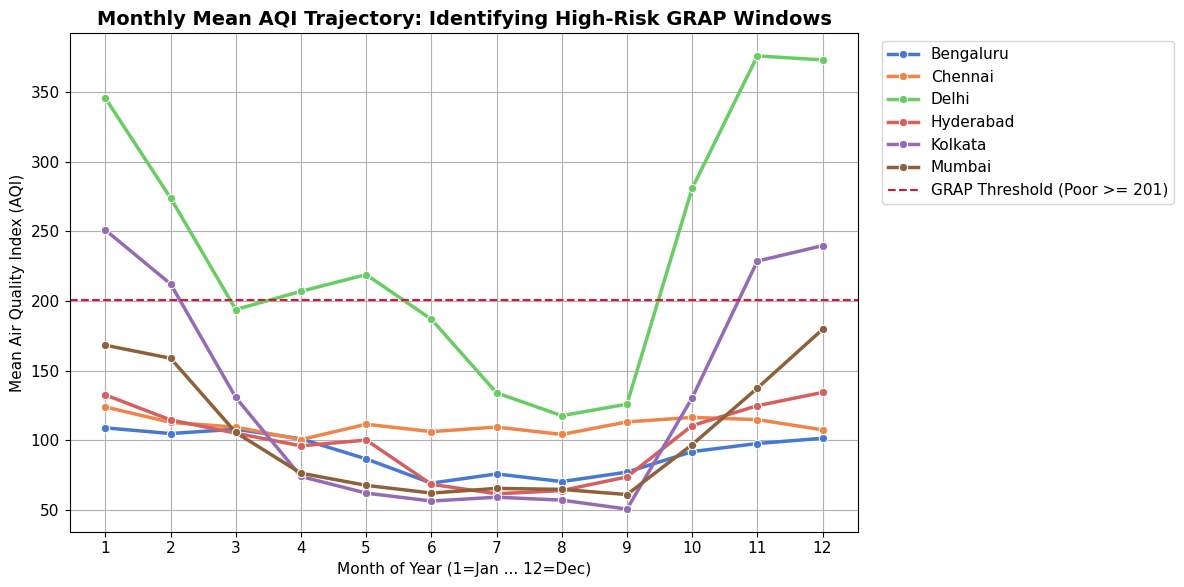

In [4]:
# --- Analysis 1: Monthly AQI Trend Across Major Metros ---
df["Month"] = df["Date"].dt.month
monthly_city_aqi = df.groupby(["Month", "City"])["AQI"].mean().reset_index()

# Select top major metropolitan clusters for clean visualization
top_cities = ["Delhi", "Mumbai", "Bengaluru", "Kolkata", "Chennai", "Hyderabad"]
filtered_monthly = monthly_city_aqi[monthly_city_aqi["City"].isin(top_cities)]

plt.figure(figsize=(12, 6))
sns.lineplot(data=filtered_monthly, x="Month", y="AQI", hue="City", marker="o", linewidth=2.5)
plt.axhline(201, color="crimson", linestyle="--", linewidth=1.5, label="GRAP Threshold (Poor >= 201)")
plt.title("Monthly Mean AQI Trajectory: Identifying High-Risk GRAP Windows", fontsize=14, fontweight="bold")
plt.xlabel("Month of Year (1=Jan ... 12=Dec)", fontsize=11)
plt.ylabel("Mean Air Quality Index (AQI)", fontsize=11)
plt.xticks(range(1, 13))
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


**Key Business Insight from Seasonal Analysis**:
* **Winter Spike (Nov–Jan)**: Delhi, Kolkata, and northern cities experience severe AQI spikes crossing the GRAP 201 threshold, driven by agricultural burning and winter temperature inversions.
* **Monsoon Dip (Jul–Sep)**: Heavy rain cleans the atmosphere across all cities, reducing AQI below 100.
* **Operational Implication**: Construction firms in Delhi & northern hubs require predictive GRAP early-warning tools primarily from **October to February**.


<Figure size 1200x600 with 0 Axes>

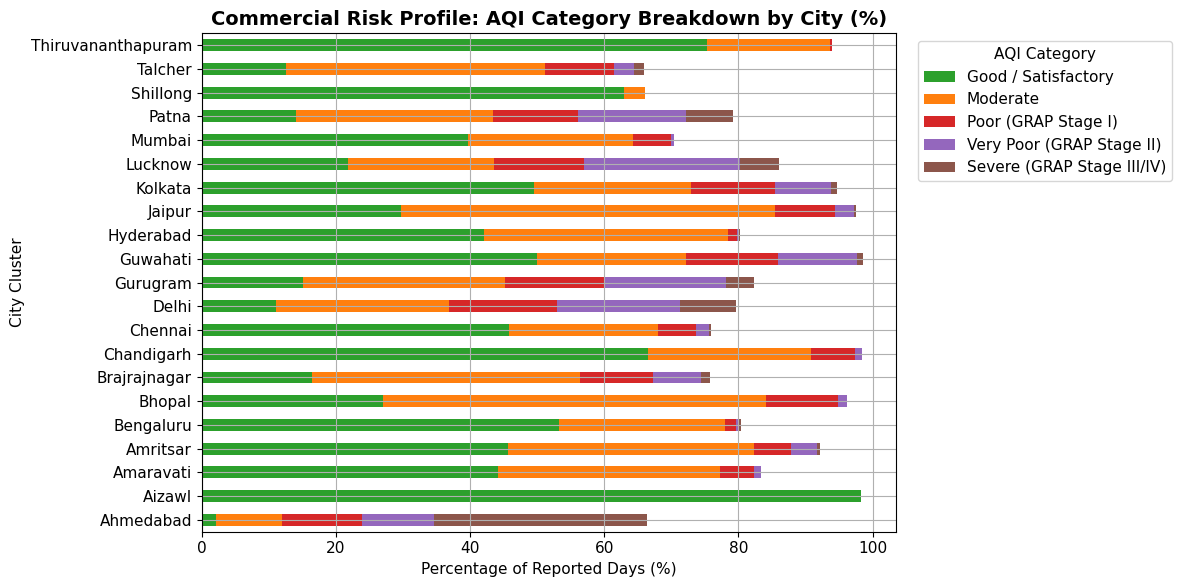

In [5]:
# --- Analysis 2: AQI Category Severity Distribution by City ---
def categorize_aqi(aqi):
    if pd.isna(aqi): return "Missing"
    if aqi <= 100: return "Good / Satisfactory"
    elif aqi <= 200: return "Moderate"
    elif aqi <= 300: return "Poor (GRAP Stage I)"
    elif aqi <= 400: return "Very Poor (GRAP Stage II)"
    else: return "Severe (GRAP Stage III/IV)"

df["AQI_Category"] = df["AQI"].apply(categorize_aqi)

# Order categories logically
cat_order = ["Good / Satisfactory", "Moderate", "Poor (GRAP Stage I)", "Very Poor (GRAP Stage II)", "Severe (GRAP Stage III/IV)"]
city_cat_counts = pd.crosstab(df["City"], df["AQI_Category"], normalize="index")[cat_order] * 100

plt.figure(figsize=(12, 6))
city_cat_counts.plot(kind="barh", stacked=True, color=["#2ca02c", "#ff7f0e", "#d62728", "#9467bd", "#8c564b"], figsize=(12, 6))
plt.title("Commercial Risk Profile: AQI Category Breakdown by City (%)", fontsize=14, fontweight="bold")
plt.xlabel("Percentage of Reported Days (%)")
plt.ylabel("City Cluster")
plt.legend(title="AQI Category", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


**Key Business Insight from Risk Profiling**:
* Cities like **Delhi, Patna, and Lucknow** experience GRAP-threshold pollution (Poor to Severe) on **over 40–50% of all reported days**.
* Southern cities (**Bengaluru, Chennai**) remain predominantly in "Good/Moderate" categories.
* **Market Target**: AirWatch's primary B2B market for commercial compliance alerts is concentrated in North & Central India.


C:\Users\Dell\AppData\Local\Temp\ipykernel_13288\2820578973.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=valid_weather, x="WindSpeed_Bin", y="AQI", palette="YlOrRd")


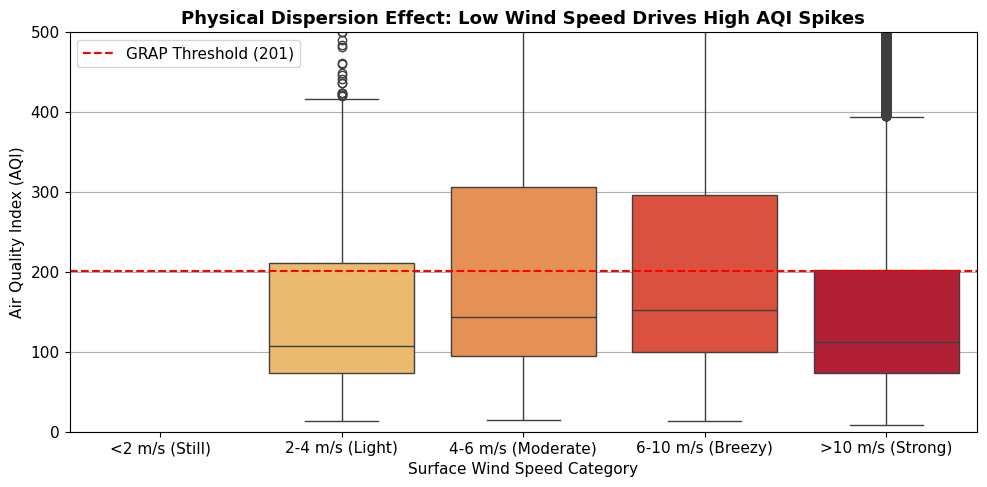

In [6]:
# --- Analysis 3: Physical Weather Drivers (Wind Speed vs AQI) ---
valid_weather = df.dropna(subset=["WindSpeed_ms", "AQI"]).copy()
valid_weather["WindSpeed_Bin"] = pd.cut(valid_weather["WindSpeed_ms"], bins=[0, 2, 4, 6, 10, 20], labels=["<2 m/s (Still)", "2-4 m/s (Light)", "4-6 m/s (Moderate)", "6-10 m/s (Breezy)", ">10 m/s (Strong)"])

plt.figure(figsize=(10, 5))
sns.boxplot(data=valid_weather, x="WindSpeed_Bin", y="AQI", palette="YlOrRd")
plt.axhline(201, color="red", linestyle="--", label="GRAP Threshold (201)")
plt.title("Physical Dispersion Effect: Low Wind Speed Drives High AQI Spikes", fontsize=13, fontweight="bold")
plt.xlabel("Surface Wind Speed Category")
plt.ylabel("Air Quality Index (AQI)")
plt.ylim(0, 500)
plt.legend()
plt.tight_layout()
plt.show()


**Key Business Insight from Weather Drivers**:
* When surface wind speed drops below **2 m/s (still air)**, mean AQI rises sharply, frequently crossing the GRAP alert threshold.
* Stronger winds ($>6	ext{ m/s}$) disperse particulate matter rapidly.
* **Model Validation**: Confirms that integrating daily wind speed and temperature inversion metrics provides critical predictive signals for 24–48h forecasts.


C:\Users\Dell\AppData\Local\Temp\ipykernel_13288\979693189.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=city_risk.head(8), x="Exposure_Risk_Index", y="City", palette="Reds_r")


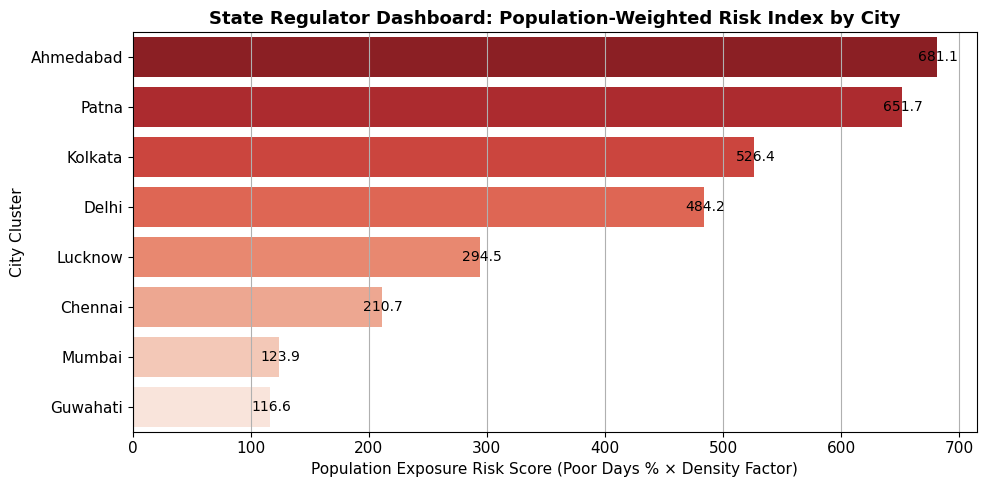

In [7]:
# --- Analysis 4: Population-Weighted Risk Prioritization Index ---
city_risk = df.groupby("City").agg(
    Avg_AQI=("AQI", "mean"),
    Poor_Days_Pct=("AQI", lambda x: (x >= 201).mean() * 100),
    Pop_Density=("PopDensity_per_km2", "first")
).reset_index()

# Calculate Population Exposure Risk Index = (Poor Days %) * (Population Density / 1000)
city_risk["Exposure_Risk_Index"] = city_risk["Poor_Days_Pct"] * (city_risk["Pop_Density"] / 1000)
city_risk = city_risk.sort_values("Exposure_Risk_Index", ascending=False)

plt.figure(figsize=(10, 5))
ax = sns.barplot(data=city_risk.head(8), x="Exposure_Risk_Index", y="City", palette="Reds_r")
plt.title("State Regulator Dashboard: Population-Weighted Risk Index by City", fontsize=13, fontweight="bold")
plt.xlabel("Population Exposure Risk Score (Poor Days % × Density Factor)")
plt.ylabel("City Cluster")

for p in ax.patches:
    width = p.get_width()
    ax.annotate(f"{width:.1f}", (width + 1.0, p.get_y() + p.get_height() / 2.),
                ha='center', va='center', fontsize=10, color='black')

plt.tight_layout()
plt.show()


**Key Business & Policy Insight**:
* **Delhi and Patna** emerge as the top priority zones for SPCB regulatory action because high pollution frequencies coincide with massive population density ($>11,000	ext{ people/km}^2$).
* **Value to Regulators**: Allows environmental agencies to deploy mobile inspection teams and dust suppression equipment to areas where health impacts are highest.


---

## 5. Initial Stage Summary & Immediate Next Steps

### 5.1 What We Have Achieved in the Initial Stage
1. **Framed the Problem**: Established a clear commercial focus on forecasting regulatory GRAP threshold crossings rather than exact raw AQI values.
2. **Assembled Multi-Source Data**: Successfully combined ground CPCB sensor readings (108,035 rows) with Open-Meteo weather API metrics (**97.3% match rate**) and WorldPop population density.
3. **Validated Physical Drivers**: Demonstrated through EDA that low wind speeds, winter inversions, and high population density create acute risk hotspots.

### 5.2 Next Steps in Development
* **Feature Engineering**: Compute 1-day ($t+1$) and 2-day ($t+2$) lag features, 7-day rolling means, and temperature inversion deltas.
* **Model Training & Faculty Ablation Study**: Train gradient boosting models (XGBoost, LightGBM) and evaluate an ablation matrix (**CPCB Only vs. CPCB + Weather vs. Full Model**) using chronological time splits (Train: 2015–2019, Test: 2020).
